In [20]:
import numpy as np
from scipy.integrate import odeint
import matplotlib.pyplot as plt

In [21]:
# Vector field

def vector_field(x, t, nu, kappa, lambda_r, lambda_c):
    r = x[0]
    theta = x[1]

    f_r = r * (lambda_r + nu * r**2)
    f_theta = lambda_c + kappa * r**2
    
    f = np.array([f_r, f_theta])

    return f

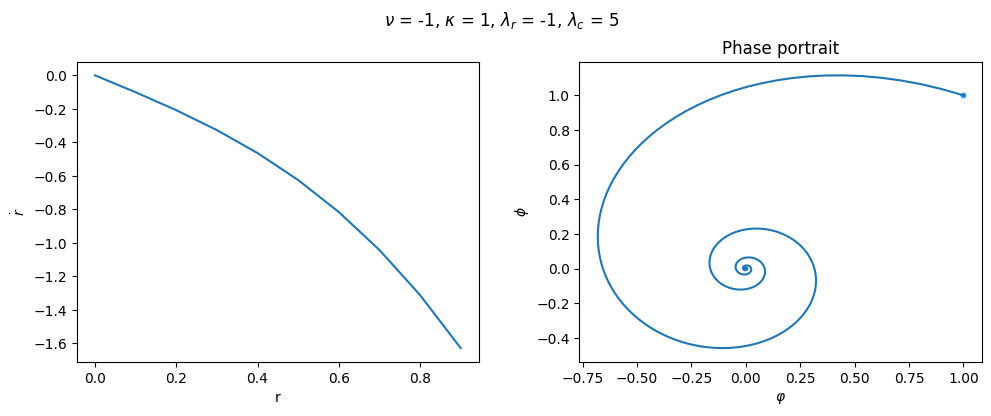

In [22]:
# nu < 0, lambda_r < 0

# parameters
nu = -1
kappa = 1
lambda_r = -1
lambda_c = 5

# plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (10, 4))
fig.subplots_adjust(left = 0.075, right = 0.98, bottom = 0.1, top = 0.85, wspace = 0.25)
fig.suptitle(rf"$\nu$ = {nu}, $\kappa$ = {kappa}, $\lambda_r$ = {lambda_r}, $\lambda_c$ = {lambda_c}")

# plot dot{r} vs r
x = np.arange(0, 1, 0.1)
f_x = x * (lambda_r + nu * x**2)

ax1.plot(x, f_x, label = "Y")

ax1.set_xlabel("r")
ax1.set_ylabel(r"$\dot{r}$")


# phase portrait
# initial condition
phi0 = 1
Phi0 = 1

r0 = np.sqrt(phi0**2 + Phi0**2)
theta0 = np.arctan(Phi0/phi0)

x0 = np.array([r0, theta0])

# time
T = 100
dt = 0.01

t = np.arange(0, T, dt)

# dynamics
x = odeint(vector_field, x0, t, (nu, kappa, lambda_r, lambda_c))

r = x[:, 0]
theta = x[:, 1]

phi = r * np.cos(theta)
Phi = r * np.sin(theta)

ax2.plot(phi0, Phi0, ".", color = "dodgerblue")
ax2.plot(phi, Phi)

ax2.set_title("Phase portrait")
ax2.set_xlabel(r"$\varphi$")
ax2.set_ylabel(r"$\phi$")

plt.savefig(f"../Figures/Normal_form/Fig_1.png")

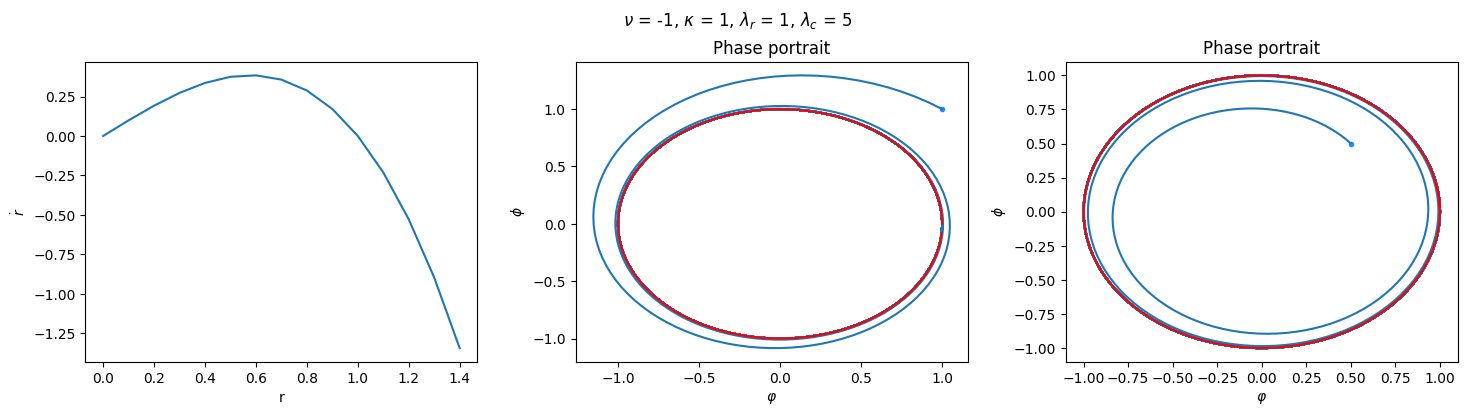

In [23]:
# nu < 0, lambda_r > 0

# parameters
nu = -1
kappa = 1
lambda_r = 1
lambda_c = 5

# plot
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize = (15, 4))
fig.subplots_adjust(left = 0.065, right = 0.98, bottom = 0.1, top = 0.85, wspace = 0.25)
fig.suptitle(rf"$\nu$ = {nu}, $\kappa$ = {kappa}, $\lambda_r$ = {lambda_r}, $\lambda_c$ = {lambda_c}")

# plot dot{r} vs r
x = np.arange(0, 1.5, 0.1)
f_x = x * (lambda_r + nu * x**2)

ax1.plot(x, f_x, label = "Y")

ax1.set_xlabel("r")
ax1.set_ylabel(r"$\dot{r}$")


# phase portrait
# initial condition outside the limiting cycle
phi0 = 1
Phi0 = 1

r0 = np.sqrt(phi0**2 + Phi0**2)
theta0 = np.arctan(Phi0/phi0)

x0 = np.array([r0, theta0])

# time
T = 100
dt = 0.01

t = np.arange(0, T, dt)

# dynamics
x = odeint(vector_field, x0, t, (nu, kappa, lambda_r, lambda_c))

r = x[:, 0]
theta = x[:, 1]

phi = r * np.cos(theta)
Phi = r * np.sin(theta)

ax2.plot(phi0, Phi0, ".", color = "dodgerblue")
ax2.plot(phi, Phi)

# limiting cycle
r = np.sqrt(-lambda_r/nu)
theta = np.arange(0, 2*np.pi, 0.1)

phi = r * np.cos(theta)
Phi = r * np.sin(theta)

ax2.plot(phi, Phi, color = "red")

ax2.set_title("Phase portrait")
ax2.set_xlabel(r"$\varphi$")
ax2.set_ylabel(r"$\phi$")

# initial condition inside the limiting cycle
phi0 = 0.5
Phi0 = 0.5

r0 = np.sqrt(phi0**2 + Phi0**2)
theta0 = np.arctan(Phi0/phi0)

x0 = np.array([r0, theta0])

# time
T = 100
dt = 0.01

t = np.arange(0, T, dt)

# dynamics
x = odeint(vector_field, x0, t, (nu, kappa, lambda_r, lambda_c))

r = x[:, 0]
theta = x[:, 1]

phi = r * np.cos(theta)
Phi = r * np.sin(theta)

ax3.plot(phi0, Phi0, ".", color = "dodgerblue")
ax3.plot(phi, Phi)

# limiting cycle
r = np.sqrt(-lambda_r/nu)
theta = np.arange(0, 2.1*np.pi, 0.1)

phi = r * np.cos(theta)
Phi = r * np.sin(theta)

ax3.plot(phi, Phi, color = "red")

ax3.set_title("Phase portrait")
ax3.set_xlabel(r"$\varphi$")
ax3.set_ylabel(r"$\phi$")

plt.savefig(f"../Figures/Normal_form/Fig_2.png")

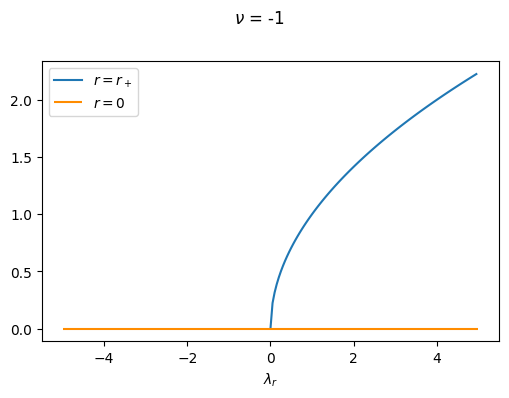

In [24]:
# bifurcation diagram:

def r_star(lambda_r, nu):
    return np.sqrt(-lambda_r/nu)

# plot
fig, ax = plt.subplots(1, 1, figsize = (5, 4))
fig.subplots_adjust(left = 0.065, right = 0.98, bottom = 0.15, top = 0.85, wspace = 0.25)
fig.suptitle(rf"$\nu$ = {nu}")

lambda_r = np.arange(0, 5, 0.05)
r_star_lambda_r = r_star(lambda_r, nu)
ax.plot(lambda_r, r_star_lambda_r, label = r"$r = r_+$")

ax.hlines(0, -5, 5, color = "darkorange", label = r"$r = 0$")

ax.set_xlabel(r"$\lambda_r$")

ax.legend()

plt.savefig(f"../Figures/Normal_form/Bifurcation_diagram_0.png")

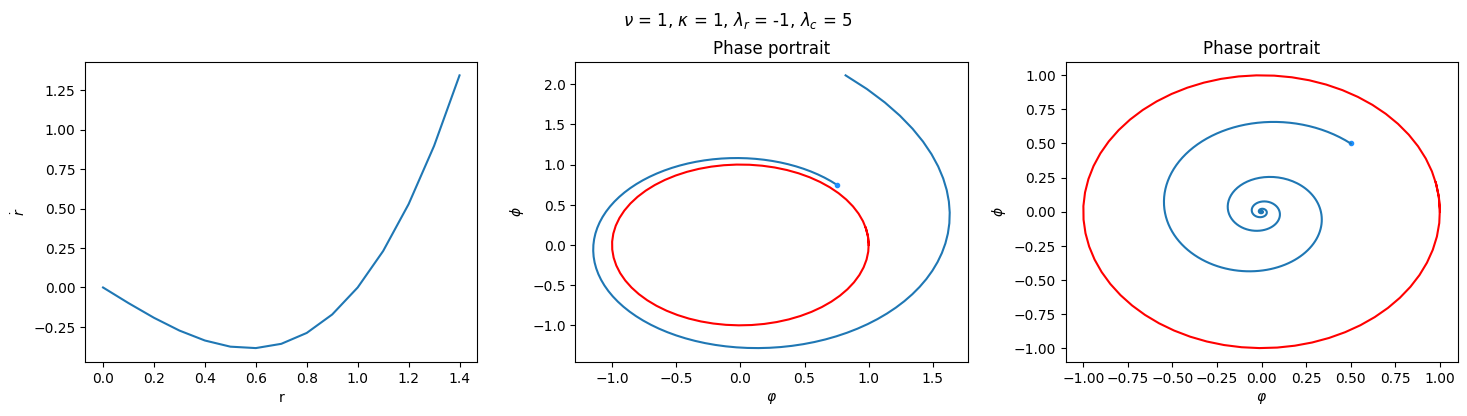

In [25]:
# nu > 0, lambda_r < 0

# parameters
nu = 1
kappa = 1
lambda_r = -1
lambda_c = 5

# plot
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize = (15, 4))
fig.subplots_adjust(left = 0.065, right = 0.98, bottom = 0.1, top = 0.85, wspace = 0.25)
fig.suptitle(rf"$\nu$ = {nu}, $\kappa$ = {kappa}, $\lambda_r$ = {lambda_r}, $\lambda_c$ = {lambda_c}")

# plot dot{r} vs r
x = np.arange(0, 1.5, 0.1)
f_x = x * (lambda_r + nu * x**2)

ax1.plot(x, f_x, label = "Y")

ax1.set_xlabel("r")
ax1.set_ylabel(r"$\dot{r}$")


# phase portrait
# initial condition outside the limiting cycle
phi0 = 0.75
Phi0 = 0.75

r0 = np.sqrt(phi0**2 + Phi0**2)
theta0 = np.arctan(Phi0/phi0)

x0 = np.array([r0, theta0])

# time
T = 1
dt = 0.01

t = np.arange(0, T, dt)

# dynamics
x = odeint(vector_field, x0, t, (nu, kappa, lambda_r, lambda_c))

r = x[:, 0]
theta = x[:, 1]

phi = r * np.cos(theta)
Phi = r * np.sin(theta)

ax2.plot(phi, Phi)

# limiting cycle
r = np.sqrt(-lambda_r/nu)
theta = np.arange(0, 2.1*np.pi, 0.1)

phi = r * np.cos(theta)
Phi = r * np.sin(theta)

ax2.plot(phi0, Phi0, ".", color = "dodgerblue")
ax2.plot(phi, Phi, color = "red")

ax2.set_title("Phase portrait")
ax2.set_xlabel(r"$\varphi$")
ax2.set_ylabel(r"$\phi$")

# initial condition inside the limiting cycle
phi0 = 0.5
Phi0 = 0.5

r0 = np.sqrt(phi0**2 + Phi0**2)
theta0 = np.arctan(Phi0/phi0)

x0 = np.array([r0, theta0])

# time
T = 100
dt = 0.01

t = np.arange(0, T, dt)

# dynamics
x = odeint(vector_field, x0, t, (nu, kappa, lambda_r, lambda_c))

r = x[:, 0]
theta = x[:, 1]

phi = r * np.cos(theta)
Phi = r * np.sin(theta)

ax3.plot(phi0, Phi0, ".", color = "dodgerblue")
ax3.plot(phi, Phi)

# limiting cycle
r = np.sqrt(-lambda_r/nu)
theta = np.arange(0, 2.1*np.pi, 0.1)

phi = r * np.cos(theta)
Phi = r * np.sin(theta)

ax3.plot(phi, Phi, color = "red")

ax3.set_title("Phase portrait")
ax3.set_xlabel(r"$\varphi$")
ax3.set_ylabel(r"$\phi$")

plt.savefig(f"../Figures/Normal_form/Fig_3.png")

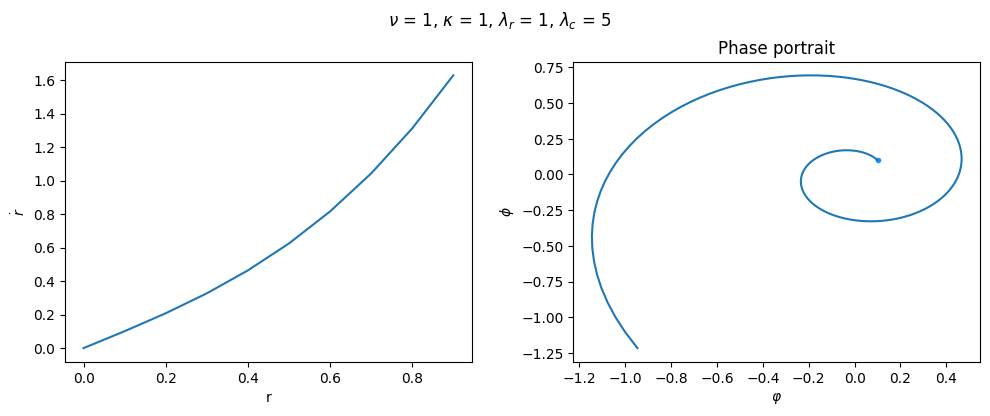

In [26]:
# nu > 0, lambda_r > 0

# parameters
nu = 1
kappa = 1
lambda_r = 1
lambda_c = 5

# plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (10, 4))
fig.subplots_adjust(left = 0.065, right = 0.98, bottom = 0.1, top = 0.85, wspace = 0.25)
fig.suptitle(rf"$\nu$ = {nu}, $\kappa$ = {kappa}, $\lambda_r$ = {lambda_r}, $\lambda_c$ = {lambda_c}")

# plot dot{r} vs r
x = np.arange(0, 1, 0.1)
f_x = x * (lambda_r + nu * x**2)

ax1.plot(x, f_x, label = "Y")

ax1.set_xlabel("r")
ax1.set_ylabel(r"$\dot{r}$")


# phase portrait
# initial condition
phi0 = 0.1
Phi0 = 0.1

r0 = np.sqrt(phi0**2 + Phi0**2)
theta0 = np.arctan(Phi0/phi0)

x0 = np.array([r0, theta0])

# time
T = 1.8
dt = 0.01

t = np.arange(0, T, dt)

# dynamics
x = odeint(vector_field, x0, t, (nu, kappa, lambda_r, lambda_c))

r = x[:, 0]
theta = x[:, 1]

phi = r * np.cos(theta)
Phi = r * np.sin(theta)

ax2.plot(phi0, Phi0, ".", color = "dodgerblue")
ax2.plot(phi, Phi)

ax2.set_title("Phase portrait")
ax2.set_xlabel(r"$\varphi$")
ax2.set_ylabel(r"$\phi$")

fig.savefig(f"../Figures/Normal_form/Fig_4.png")

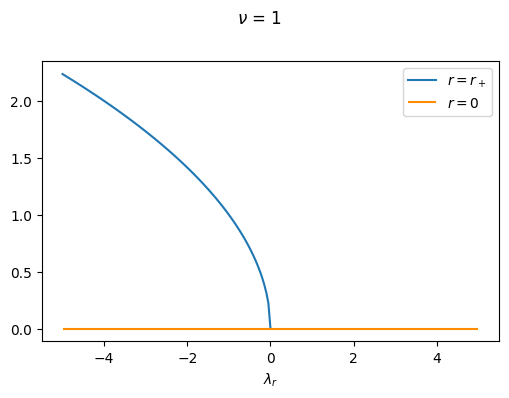

In [27]:
# bifurcation diagram:

# plot
fig, ax = plt.subplots(1, 1, figsize = (5, 4))
fig.subplots_adjust(left = 0.065, right = 0.98, bottom = 0.15, top = 0.85, wspace = 0.25)
fig.suptitle(rf"$\nu$ = {nu}")

lambda_r = np.arange(-5, 0.05, 0.05)
r_star_lambda_r = r_star(lambda_r, nu)
ax.plot(lambda_r, r_star_lambda_r, label = r"$r = r_+$")

ax.hlines(0, -5, 5, color = "darkorange", label = r"$r = 0$")

ax.set_xlabel(r"$\lambda_r$")

ax.legend()

plt.savefig(f"../Figures/Normal_form/Bifurcation_diagram_1.png")